# 01 — Data Audit, Causal Alignment, and Chronological Split 

In [1]:
import numpy as np
import pandas as pd

import common as C

C.ensure_dirs()
df_raw = C.load_raw()
print("Raw shape:", df_raw.shape)
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))
print("Missing/invalid timestamps:", int(pd.to_numeric(df_raw["Timestamp"], errors="coerce").isna().sum()))

df_sorted = df_raw.sort_values(["ID", "Timestamp"]).reset_index(drop=True)
print("Repeated (ID, Timestamp) rows:", int(df_sorted.duplicated(["ID", "Timestamp"]).sum()))
df_sorted["interval_s"] = df_sorted.groupby("ID")["Timestamp"].diff()
print("\nSampling interval summary per device (seconds):")
print(df_sorted.groupby("ID")["interval_s"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2))

Raw shape: (65733, 8)
Exact duplicate rows: 0
Missing/invalid timestamps: 0
Repeated (ID, Timestamp) rows: 0

Sampling interval summary per device (seconds):
              count  mean   std  min  50%  90%  95%  99%    max
ID                                                             
Ampli1      10961.0  3.26  3.45  3.0  3.0  4.0  4.0  4.0  361.0
Ampli2      10961.0  3.26  3.45  3.0  3.0  4.0  4.0  4.0  361.0
Ampli3      10948.0  3.26  3.45  3.0  3.0  4.0  4.0  4.0  361.0
Ampli4      10948.0  3.26  3.45  3.0  3.0  4.0  4.0  4.0  360.0
SPO1/18/11  10961.0  3.26  3.44  3.0  3.0  4.0  4.0  4.0  360.0
SPO2/18/11  10948.0  3.26  3.45  3.0  3.0  4.0  4.0  4.0  361.0


In [2]:
# Phase audit on raw records
phase_audit = df_raw.copy()
phase_audit["phase"] = C.assign_phase(phase_audit["Timestamp"])
phase_audit["is_failure"] = phase_audit["Failure"].eq(1)
phase_audit["label_missing"] = phase_audit["Failure"].isna()
phase_summary = phase_audit.groupby("phase").agg(
    raw_records=("Failure", "size"),
    failure_records=("is_failure", "sum"),
    missing_labels=("label_missing", "sum"),
    first_timestamp=("Timestamp", "min"),
    last_timestamp=("Timestamp", "max"),
)
print(phase_summary)
assert phase_audit.loc[phase_audit["is_failure"] & phase_audit["phase"].ne("P3_fault_experiments")].empty

                                raw_records  failure_records  missing_labels  \
phase                                                                          
P1_normal                             39676                0           39676   
P2_normal_variable_attenuation        13660                0           13660   
P3_fault_experiments                  12397             2485            9912   

                                first_timestamp  last_timestamp  
phase                                                            
P1_normal                            1623394634      1623416337  
P2_normal_variable_attenuation       1623416338      1623423686  
P3_fault_experiments                 1623423687      1623430365  


In [3]:
# Candidate episode grouping sensitivity
failure_times = np.sort(df_raw.loc[df_raw["Failure"].eq(1), "Timestamp"].unique())
ep_sens = []
for g in [5, 7, 10.5, 14]:
    cand = C.candidate_episodes(df_raw, max_gap_s=g)
    ep_sens.append({
        "grouping_gap_s": g,
        "candidate_episodes": len(cand),
        "median_observed_span_s": cand["observed_span_s"].median(),
        "max_observed_span_s": cand["observed_span_s"].max(),
        "mean_start_to_start_s": round(float(cand["start_to_start_s"].mean()), 2),
    })
ep_sens_df = pd.DataFrame(ep_sens)
print("\nEpisode grouping sensitivity:")
print(ep_sens_df)

episodes_candidate = C.candidate_episodes(df_raw, max_gap_s=7.0)
episodes_candidate.to_csv(C.OUT / "episodes_candidate.csv", index=False)


Episode grouping sensitivity:
   grouping_gap_s  candidate_episodes  median_observed_span_s  \
0             5.0                 131                    10.0   
1             7.0                 131                    10.0   
2            10.5                 131                    10.0   
3            14.0                 131                    10.0   

   max_observed_span_s  mean_start_to_start_s  
0                   17                  51.32  
1                   17                  51.32  
2                   17                  51.32  
3                   17                  51.32  


In [4]:
# Build 1-second causal detection table + Stage-2 chronological split
aligned, feature_cols, value_cols = C.build_aligned(
    df_raw, age_limit_s=C.AGE_LIMIT_S, label_max_age_s=C.DEFAULT_LABEL_MAX_AGE_S, keep_audit=False
)
split, split_manifest = C.build_split(aligned, episodes_candidate, context_s=10, partition_gap_s=30)
aligned["split"] = split

print("\nTarget counts (all 35,732 decision seconds):")
print(aligned["target"].value_counts(dropna=False))
print("\nSplit x Target counts:")
split_target_ct = pd.crosstab(aligned["split"], aligned["target"].astype("string").fillna("unknown"))
print(split_target_ct)

print("\nSplit x Phase counts:")
print(pd.crosstab(aligned["split"], aligned["phase"]))

print("\nEpisodes per partition:")
print(split_manifest["split"].value_counts())

aligned.to_parquet(C.OUT / "aligned_detection_table.parquet", index=False)
split_manifest.to_csv(C.OUT / "split_manifest.csv", index=False)
print("\nSaved aligned_detection_table.parquet and split_manifest.csv")


Target counts (all 35,732 decision seconds):
target
0       33576
<NA>     1188
1         968
Name: count, dtype: Int64

Split x Target counts:
target          0    1  unknown
split                          
excluded      116   32       14
test         1011  210      100
train       31539  546      912
validation    910  180      162

Split x Phase counts:
phase       P1_normal  P2_normal_variable_attenuation  P3_fault_experiments
split                                                                      
excluded            0                               0                   162
test                0                               0                  1321
train           21704                            7349                  3944
validation          0                               0                  1252

Episodes per partition:
split
train         77
test          26
validation    24
excluded       4
Name: count, dtype: int64

Saved aligned_detection_table.parquet and split_manifest.c

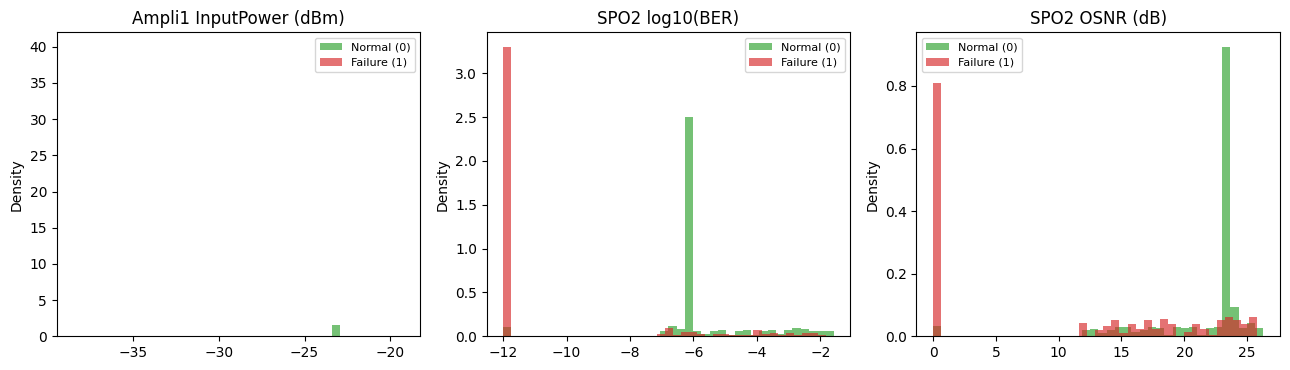

In [5]:
# EDA visualization: Normal vs Failure distributions (rendered inline in notebook)
import matplotlib.pyplot as plt

df_log = C.add_log_ber(aligned)
known = df_log[df_log["target"].notna()]
norm = known[known["target"] == 0]
fail = known[known["target"] == 1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (col, label) in zip(
    axes,
    [("Ampli1_InputPower", "Ampli1 InputPower (dBm)"), ("SPO2_18_11_BER", "SPO2 log10(BER)"), ("SPO2_18_11_OSNR", "SPO2 OSNR (dB)")],
):
    ax.hist(norm[col].dropna(), bins=40, density=True, alpha=0.65, color="#2ca02c", label="Normal (0)")
    ax.hist(fail[col].dropna(), bins=40, density=True, alpha=0.65, color="#d62728", label="Failure (1)")
    ax.set_title(label)
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(C.FIG_DIR / "eda_distributions.png", dpi=150)
plt.show()